# Hyperliquid block timing — distribution, dependence, forecastability, Binance lead

**Target:** Hyperliquid exchange block time (`ts_exch_ns`, integer ms), not arrival at the VM.

**What counts as "predictable" (Mark, 2026-10-18):**
1. the block interval can be modelled as some distribution,
2. there is autocorrelation,
3. the next block can be forecast *within a confidence interval* conditioned on previous blocks
   (e.g. a lot of trading in the previous block),
4. Binance activity *inside* HL's gaps leads what HL does next,
5. all of the above across the 6 instruments, comparing crypto perps vs tradfi (HIP-3 `xyz:`) perps.

**Status:** exploratory, *unregistered*. `qr-harness_v2` has no `qrlib` (prereg/pit/leakage/audit),
so the card gate and the harness leakage gate can't run. This notebook carries its own truncation
test (§6) and a trial counter instead.

**The structural caveat that runs through everything:** the feed has no block height. A block is
only *visible* when at least one of the 6 subscribed instruments changed BBO or traded in it. Observed
gaps = (sum of k latent block intervals), k ≥ 1. Activity raises visibility, so "more activity → shorter
gaps" is partly a sampling artefact. Every activity result below is reported on **single-block gaps**
too, which is where the clock itself is measured.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
import statsmodels.api as sm
from scipy import optimize, stats
from scipy.special import expit, softmax
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import log_loss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

# dataviz reference palette: slot 1 blue = crypto, slot 2 orange = tradfi, slot 3 aqua = model fits
C_CRYPTO, C_TRADFI, C_FIT, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "lines.linewidth": 2,
    "font.size": 9,
})

## 1. KNOBS
Every tunable choice lives here. `# ASSUMPTION:` marks choices Mark didn't specify.

In [2]:
DATA_ROOT = Path("../market_data_v2/normalized")

# HL symbol -> Binance USDT-perp. ASSUMPTION: xyz:SP500 is paired with Binance SPY (ETF ~ index/10;
# returns comparable, levels not). xyz:CL ~ CL-USDT, xyz:TSLA ~ TSLA-USDT.
PAIRS = {
    "BTC-USD-PERP": "BTC-USDT-PERP",
    "HYPE-USD-PERP": "HYPE-USDT-PERP",
    "AAVE-USD-PERP": "AAVE-USDT-PERP",
    "xyz:SP500-USD-PERP": "SPY-USDT-PERP",
    "xyz:TSLA-USD-PERP": "TSLA-USDT-PERP",
    "xyz:CL-USD-PERP": "CL-USDT-PERP",
}
GROUP = {s: ("tradfi" if s.startswith("xyz:") else "crypto") for s in PAIRS}
SYMS = list(PAIRS)

TRAIN_FRAC = 0.6        # ASSUMPTION: chronological 60/40 split by HL block time; no shuffling.
GMAX = 600              # ASSUMPTION: distribution fits use gaps <= 600 ms (covers ~99% of union gaps).
KMAX = 8                # max latent blocks per observed gap in the lattice model.
SINGLE_POST = 0.90      # ASSUMPTION: a gap is "single-block" if P(k=1 | gap) >= 0.90 under the train fit.
ACF_LAGS = 20
LB_LAGS = [1, 5, 10, 20]
HAC_LAGS = 20           # Newey-West lags for Wald tests.
ACT_HIGH_Q = 0.80       # ASSUMPTION: "high activity" = top quintile of the activity measure (train cut).
QUANTILES = [0.1, 0.5, 0.9]   # forecast interval = [q10, q90], nominal 80% coverage.
HGB_KW = dict(max_iter=200, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200,
              early_stopping=False, random_state=0)   # ASSUMPTION: fixed, untuned (no tuning = fewer trials).
BOOT_REPS, BOOT_BLOCK = 400, 500   # moving-block bootstrap on test losses (block = 500 consecutive obs).
HAZ_STEP, HAZ_TMAX = 10, 600       # within-gap hazard grid (ms).
# Latency = time from an exchange timestamp until we *know* the event. Only the forecasting section (Q5) uses it:
# a forecast made "at block n" can only use what has arrived by then. Q1-Q4, the hazard and the lead analysis stay
# pure exchange-time descriptions of the process. Two scenarios are run side by side:
LATENCY_SCENARIOS = {
    # Mark's figure (2026-10-19). ASSUMPTION: the same N(0.50, 0.05) ms is applied to Binance (Mark gave it for HL only).
    "N(0.50, 0.05) ms": dict(kind="normal", hl=(0.50, 0.05), bn=(0.50, 0.05)),
    # Each message's actual arrival on the VM (ts_recv). ASSUMPTION: VM clock and exchange clocks are in sync.
    "measured ts_recv": dict(kind="recv"),
}
LEAD_SHIFTS = np.arange(-1000, 501, 10)  # price-lead profile shifts (ms, Binance relative to HL).
WITHIN_DELTAS = [10, 30, 60]       # Binance return measured up to (next HL update - delta).
EVT_RET_MS = 50          # event study: a Binance "jump" = |mid return over 50 ms| ...
EVT_Q = 0.995            # ... in the top 0.5% for that pair. ASSUMPTION: threshold picked to get ~100s of events.
EVT_MIN_SEP = 2000       # keep jumps >= 2 s apart so the windows don't overlap.
EVT_WIN = np.arange(-1000, 2001, 10)   # ms around the jump.
SEED = 0

TRIALS = []   # every evaluated model variant is appended here; n_trials reported at the end.
def log_trial(**kw):
    TRIALS.append(kw)

## 2. Data
* HL `l1` (= `bbo` channel, event-driven) and `trades` for the 6 symbols. `l2` is ~5.4 s snapshots → unused.
* HL trades replay a snapshot on every (re)subscribe; rows executed before their connection opened are dropped.
  The same filter is applied to `l1`.
* Binance: `l1` uses `ts_txn_ns` (bookTicker `T`, matching-engine time); trades use `ts_trade_ns` (`T`).
  ASSUMPTION: `T` is the closest Binance analogue to HL block time. Binance trade `E` lags `T` by ~150 ms.

In [3]:
def _sym(s):
    return s.replace("", ":")   # rclone writes ':' as U+F03A in Windows folder names

def load(table, venue, cols):
    d = ds.dataset(DATA_ROOT / f"table={table}", format="parquet", partitioning="hive")
    df = d.to_table(filter=ds.field("venue") == venue, columns=cols + ["symbol"]).to_pandas()
    df["symbol"] = df["symbol"].astype(str).map(_sym)
    return df

sess = ds.dataset(DATA_ROOT / "table=sessions", format="parquet", partitioning="hive").to_table().to_pandas()
hl_open = (sess[(sess.venue == "HYPERLIQUID") & (sess.kind == "ws") & (~sess.resumed)]
           .groupby("ordinal").opened_ns.min())
print("HL ws connections (ordinal -> opened):", {k: str(pd.to_datetime(v)) for k, v in hl_open.items()})

hl_l1 = load("l1", "HYPERLIQUID", ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "bid_px", "ask_px"])
hl_tr = load("trades", "HYPERLIQUID", ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "price", "size"])
hl_l1 = hl_l1[hl_l1.symbol.isin(SYMS)]
hl_tr = hl_tr[hl_tr.symbol.isin(SYMS)]

def drop_replays(df, name):
    opened = df.conn_ordinal.map(hl_open)
    bad = df.ts_exch_ns < opened
    print(f"{name}: dropped {bad.sum()} rows executed before their connection opened (subscribe replay)")
    return df[~bad].copy()

hl_l1 = drop_replays(hl_l1, "HL l1")
hl_tr = drop_replays(hl_tr, "HL trades")
for df in (hl_l1, hl_tr):
    df["t"] = df.ts_exch_ns // 1_000_000           # integer ms, exact (feed is ms resolution)
hl_l1["lmid"] = np.log((hl_l1.bid_px + hl_l1.ask_px) / 2)
hl_tr["notional"] = hl_tr.price * hl_tr.size

bn_l1 = load("l1", "BINANCE_FUTURES", ["ts_txn_ns", "ts_recv_ns", "bid_px", "ask_px"])
bn_tr = load("trades", "BINANCE_FUTURES", ["ts_trade_ns", "ts_recv_ns", "price", "size"])
bn_l1["t"] = np.round(bn_l1.ts_txn_ns / 1e6).astype("int64")
bn_tr["t"] = bn_tr.ts_trade_ns // 1_000_000
for df in (hl_l1, hl_tr, bn_l1, bn_tr):
    df["recv"] = df.ts_recv_ns / 1e6            # VM arrival, float ms (used only by the latency scenarios)
bn_l1["lmid"] = np.log((bn_l1.bid_px + bn_l1.ask_px) / 2)

span = pd.to_datetime([hl_l1.t.min(), hl_l1.t.max()], unit="ms")
print(f"HL span {span[0]} -> {span[1]}  ({(span[1]-span[0]).total_seconds()/3600:.2f} h, "
      f"weekday={span[0].day_name()})")
print(pd.DataFrame({
    "HL l1": hl_l1.symbol.value_counts(), "HL trades": hl_tr.symbol.value_counts(),
    "BN l1": bn_l1.symbol.map({v: k for k, v in PAIRS.items()}).value_counts(),
    "BN trades": bn_tr.symbol.map({v: k for k, v in PAIRS.items()}).value_counts(),
}).loc[SYMS])

HL ws connections (ordinal -> opened): {1: '2026-10-18 03:14:20.942266703', 2: '2026-10-18 06:11:48.873706341', 3: '2026-10-18 09:06:28.603243589'}


HL l1: dropped 4 rows executed before their connection opened (subscribe replay)
HL trades: dropped 541 rows executed before their connection opened (subscribe replay)


HL span 2026-10-18 03:14:20.960000 -> 2026-10-18 10:23:50.290000  (7.16 h, weekday=Sunday)


                     HL l1  HL trades    BN l1  BN trades
symbol                                                   
BTC-USD-PERP        121325      47900  5262096     157637
HYPE-USD-PERP        96571      41031  1211737      79898
AAVE-USD-PERP        48453       3253   282315      20959
xyz:SP500-USD-PERP   30868      24974   196058       3501
xyz:TSLA-USD-PERP    11929       2831    87783       6578
xyz:CL-USD-PERP      18472       3661   139671       5891


### 2.1 Block table
A *visible block* = a distinct HL `t` (ms) carrying any l1 update or trade on any of the 6 symbols.
Gaps that span a reconnect are dropped (the outage would masquerade as a long block).

In [4]:
ev = pd.concat([
    hl_l1[["symbol", "t", "recv", "conn_ordinal"]].assign(n_l1=1, n_tr=0, notional=0.0),
    hl_tr[["symbol", "t", "recv", "conn_ordinal", "notional"]].assign(n_l1=0, n_tr=1),
], ignore_index=True)
blk_recv = ev.groupby("t").recv.max()   # a block is fully known once its last message has arrived
ev["grp"] = ev.symbol.map(GROUP)

blk = ev.groupby("t").agg(n_l1=("n_l1", "sum"), n_tr=("n_tr", "sum"), notional=("notional", "sum"),
                          n_sym=("symbol", "nunique"), ordinal=("conn_ordinal", "min"))
grp_cnt = ev.groupby(["t", "grp"]).size().unstack(fill_value=0)
blk["upd_crypto"] = grp_cnt.get("crypto", 0)
blk["upd_tradfi"] = grp_cnt.get("tradfi", 0)
blk = blk.reset_index()
blk["gap"] = blk.t.diff()
blk.loc[blk.ordinal != blk.ordinal.shift(), "gap"] = np.nan   # first block / reconnect-spanning gap
print(f"visible blocks: {len(blk):,}; valid gaps: {blk.gap.notna().sum():,}")

# per-instrument update streams: distinct t where that symbol updated (l1 or trade)
inst = {}
for s in SYMS:
    e = ev[ev.symbol == s].groupby("t").agg(n_l1=("n_l1", "sum"), n_tr=("n_tr", "sum"),
                                             notional=("notional", "sum"), ordinal=("conn_ordinal", "min")).reset_index()
    e["gap"] = e.t.diff()
    e.loc[e.ordinal != e.ordinal.shift(), "gap"] = np.nan
    inst[s] = e

T_SPLIT = blk.t.quantile(TRAIN_FRAC)
print("train/test split at", pd.to_datetime(T_SPLIT, unit="ms"))

visible blocks: 202,361; valid gaps: 202,358


train/test split at 2026-10-18 07:40:46.012000


### 2.2 Do all 6 instruments share one block clock?
If the HIP-3 `xyz:` dex ran on a different clock, its timestamps wouldn't coincide with main-dex ones.

In [5]:
tsets = {s: set(inst[s].t) for s in SYMS}
rows = []
for s in SYMS:
    others = set().union(*[tsets[o] for o in SYMS if o != s])
    other_grp = set().union(*[tsets[o] for o in SYMS if GROUP[o] != GROUP[s]])
    rows.append({"symbol": s, "group": GROUP[s], "visible_blocks": len(tsets[s]),
                 "share_of_union": len(tsets[s]) / len(blk),
                 "ts_shared_with_any_other": len(tsets[s] & others) / len(tsets[s]),
                 "ts_shared_with_other_group": len(tsets[s] & other_grp) / len(tsets[s])})
clock = pd.DataFrame(rows).set_index("symbol")
clock

,group,visible_blocks,share_of_union,ts_shared_with_any_other,ts_shared_with_other_group
symbol,,,,,
BTC-USD-PERP,crypto,121431,0.6001,0.5887,0.2133
HYPE-USD-PERP,crypto,96641,0.4776,0.6542,0.2113
AAVE-USD-PERP,crypto,48460,0.2395,0.7774,0.2180
xyz:SP500-USD-PERP,tradfi,30918,0.1528,0.6821,0.6481
xyz:TSLA-USD-PERP,tradfi,11934,0.0590,0.7557,0.6985
xyz:CL-USD-PERP,tradfi,18485,0.0913,0.7133,0.6709


## 3. Q1 — Is the block interval consistent with a distribution?

**H0:** observed gaps follow F(θ). Candidates, all fit by ML on the **train** histogram (gaps ≤ GMAX) and scored on **test**:
* **M0 exponential** — memoryless (Poisson block arrivals). The "no clock" null.
* **M1 shifted lognormal** — a smooth single-mode duration, no lattice.
* **M2a lattice, rigid clock** — gap = sum of k blocks, each block ~ Normal(μ, σ) (σ absorbs ms rounding); k has free weights.
* **M2b lattice, clock + slow blocks** — block ~ π·Normal(μ, σ) + (1−π)·(shift + Gamma). The Gamma part lets some
  blocks run long (or short) without needing a skipped block.

ASSUMPTION: k (how many blocks were invisible) is independent of the block durations. It isn't exactly — a long block
has more time to accumulate a visible change — so k-weights are descriptive, not structural.

In [6]:
grid = np.arange(GMAX + 1, dtype=float)

def _disc(cdf):
    p = cdf(grid + 0.5) - cdf(grid - 0.5)
    p[0] = 0.0
    return np.clip(p, 0, None)

def block_pmf(th, rigid):
    mu, lsig = th[0], th[1]
    core = _disc(lambda x: stats.norm.cdf(x, mu, np.exp(lsig)))
    if rigid:
        b = core
    else:
        pi, shift, a, sc = expit(th[2]), th[3], np.exp(th[4]), np.exp(th[5])
        tail = _disc(lambda x: stats.gamma.cdf(x - shift, a, scale=sc))
        b = pi * core + (1 - pi) * tail
    return b / b.sum()

def lattice_pmf(th, rigid, return_k=False):
    nb = 2 if rigid else 6
    b, w = block_pmf(th[:nb], rigid), softmax(th[nb:])
    comps, bk = [], b.copy()
    for k in range(KMAX):
        comps.append(w[k] * bk)
        bk = np.convolve(bk, b)[: GMAX + 1]
    comps = np.array(comps)
    tot = comps.sum(0)
    z = tot.sum()
    return (comps / z, tot / z) if return_k else tot / z

MODELS = {
    "M0 exponential": dict(n=1, x0=[np.log(150.0)],
                           pmf=lambda th: (lambda p: p / p.sum())(_disc(lambda x: stats.expon.cdf(x, scale=np.exp(th[0]))))),
    "M1 shifted lognormal": dict(n=3, x0=[30.0, np.log(60.0), np.log(0.8)],
                                 pmf=lambda th: (lambda p: p / p.sum())(_disc(lambda x: stats.lognorm.cdf(x - th[0], np.exp(th[2]), scale=np.exp(th[1]))))),
    "M2a lattice rigid": dict(n=2 + KMAX, x0=[67.0, np.log(1.5)] + list(-0.5 * np.arange(KMAX)),
                              pmf=lambda th: lattice_pmf(th, rigid=True)),
    "M2b lattice + slow blocks": dict(n=6 + KMAX, x0=[67.0, np.log(1.5), 0.0, 40.0, np.log(2.0), np.log(15.0)] + list(-0.5 * np.arange(KMAX)),
                                      pmf=lambda th: lattice_pmf(th, rigid=False)),
}

def hist(g):
    g = g[(g >= 0) & (g <= GMAX)].astype(int)
    return np.bincount(g, minlength=GMAX + 1).astype(float)

def nll(th, pmf, counts):
    return -(counts * np.log(pmf(th) + 1e-300)).sum()

def fit_all(gaps_train, gaps_test, label):
    htr, hte = hist(gaps_train), hist(gaps_test)
    out, fits = [], {}
    for name, m in MODELS.items():
        r = optimize.minimize(nll, m["x0"], args=(m["pmf"], htr), method="L-BFGS-B")
        if "lattice" in name:   # second start from a wider clock to avoid a bad local optimum
            x1 = np.array(m["x0"], float); x1[1] = np.log(3.0)
            r2 = optimize.minimize(nll, x1, args=(m["pmf"], htr), method="L-BFGS-B")
            r = r2 if r2.fun < r.fun else r
        fits[name] = r.x
        p = m["pmf"](r.x)
        exp_te = hte.sum() * p
        cdf_gap = np.abs(np.cumsum(hte) / hte.sum() - np.cumsum(p)).max()
        # chi-square GOF on test, bins merged until expected >= 5
        o, e, ob, eb = [], [], 0.0, 0.0
        for oi, ei in zip(hte, exp_te):
            ob += oi; eb += ei
            if eb >= 5:
                o.append(ob); e.append(eb); ob = eb = 0.0
        if o:
            o[-1] += ob; e[-1] += eb
        chi2 = (((np.array(o) - np.array(e)) ** 2) / np.array(e)).sum()
        dof = len(o) - 1 - m["n"]
        out.append({"set": label, "model": name, "k_params": m["n"],
                    "train_nll_per_obs": r.fun / htr.sum(),
                    "test_nll_per_obs": nll(r.x, m["pmf"], hte) / hte.sum(),
                    "test_AIC": 2 * nll(r.x, m["pmf"], hte) + 2 * m["n"],
                    "chi2/dof": chi2 / dof, "GOF p": stats.chi2.sf(chi2, dof), "max|CDF diff|": cdf_gap,
                    "n_train": int(htr.sum()), "n_test": int(hte.sum())})
        log_trial(q="Q1", set=label, model=name)
    return pd.DataFrame(out), fits

g_all = blk.gap.dropna()
is_tr = blk.t <= T_SPLIT
q1_tab, q1_fits = fit_all(blk.gap[is_tr].dropna().values, blk.gap[~is_tr].dropna().values, "union")
q1_tab.set_index("model").drop(columns="set")

,k_params,train_nll_per_obs,test_nll_per_obs,test_AIC,chi2/dof,GOF p,max|CDF diff|,n_train,n_test
model,,,,,,,,,
M0 exponential,1,5.8235,5.7578,927101.2114,609.2494,0.0,0.3138,120364,80508
M1 shifted lognormal,3,5.3826,5.2676,848168.1325,357.1764,0.0,0.1771,120364,80508
M2a lattice rigid,10,5.0385,4.9525,797459.1233,156.8577,0.0,0.1040,120364,80508
M2b lattice + slow blocks,14,4.7662,4.7424,763627.3627,42.2208,0.0,0.0703,120364,80508


In [7]:
th = q1_fits["M2b lattice + slow blocks"]
mu, sig, pi = th[0], np.exp(th[1]), expit(th[2])
bpmf = block_pmf(th[:6], rigid=False)
comps, tot = lattice_pmf(th, rigid=False, return_k=True)
post1 = comps[0] / np.maximum(tot, 1e-300)
# single-block threshold: last ms (after the core) where P(k=1|gap) is still >= SINGLE_POST
mode = int(np.argmax(bpmf))
thr_hi = mode + int(np.argmax(post1[mode:] < SINGLE_POST)) - 1
thr_lo = 1
SINGLE_MAX = thr_hi
w = softmax(th[6:])
bmean = (grid * bpmf).sum()
print(f"M2b block clock: core mu={mu:.2f} ms, sigma={sig:.2f} ms, share of blocks on the core={pi:.1%}")
print(f"implied mean block = {bmean:.1f} ms  -> {1000/bmean:.2f} blocks/s;  block-pmf median = {np.searchsorted(np.cumsum(bpmf), .5)} ms")
print("P(k) among gaps <= GMAX:", {k + 1: round(float(x), 3) for k, x in enumerate(w)})
print(f"single-block gaps: gap <= {SINGLE_MAX} ms (P(k=1|gap) >= {SINGLE_POST})")
blocks_seen = len(blk) / ((blk.t.max() - blk.t.min()) / bmean)
print(f"visible blocks / implied blocks = {blocks_seen:.1%}")

M2b block clock: core mu=67.04 ms, sigma=1.46 ms, share of blocks on the core=64.7%
implied mean block = 68.1 ms  -> 14.69 blocks/s;  block-pmf median = 67 ms
P(k) among gaps <= GMAX: {1: 0.523, 2: 0.275, 3: 0.118, 4: 0.035, 5: 0.022, 6: 0.017, 7: 0.006, 8: 0.004}
single-block gaps: gap <= 99 ms (P(k=1|gap) >= 0.9)
visible blocks / implied blocks = 53.4%


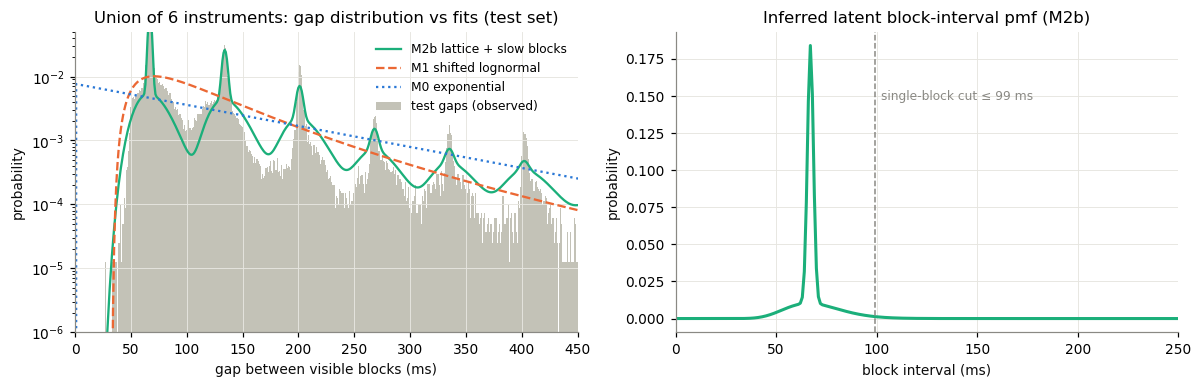

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
hte = hist(blk.gap[~is_tr].dropna().values)
x = grid
ax[0].bar(x, hte / hte.sum(), width=1.0, color="#c3c2b7", label="test gaps (observed)")
for name, ls, col in [("M2b lattice + slow blocks", "-", C_FIT), ("M1 shifted lognormal", "--", C_TRADFI), ("M0 exponential", ":", C_CRYPTO)]:
    ax[0].plot(x, MODELS[name]["pmf"](q1_fits[name]), ls, color=col, lw=1.5, label=name)
ax[0].set(xlim=(0, 450), yscale="log", ylim=(1e-6, 0.05), xlabel="gap between visible blocks (ms)", ylabel="probability",
          title="Union of 6 instruments: gap distribution vs fits (test set)")
ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(x, bpmf, color=C_FIT, label="fitted single-block interval")
ax[1].axvline(SINGLE_MAX, color=C_MUTED, lw=1, ls="--")
ax[1].text(SINGLE_MAX + 3, bpmf.max() * 0.8, f"single-block cut ≤ {SINGLE_MAX} ms", color=C_MUTED, fontsize=8)
ax[1].set(xlim=(0, 250), xlabel="block interval (ms)", ylabel="probability", title="Inferred latent block-interval pmf (M2b)")
plt.tight_layout(); plt.show()

### 3.1 Per instrument
Each instrument only sees the blocks where *it* changed. Gaps in **block units** (gap / mean block) show how much
of the clock each instrument observes. The clock is chain-wide, so differences here are about *visibility*, not timing.

In [9]:
rows = []
for s in SYMS:
    g = inst[s].gap.dropna()
    k = np.round(g / bmean)
    rows.append({"symbol": s, "group": GROUP[s], "n_gaps": len(g), "median gap ms": g.median(),
                 "p90 gap ms": g.quantile(.9), "share single-block (≤cut)": (g <= SINGLE_MAX).mean(),
                 "median k (blocks)": k.median(), "share of all blocks visible": len(inst[s]) / ((inst[s].t.max() - inst[s].t.min()) / bmean)})
q1_inst = pd.DataFrame(rows).set_index("symbol")
q1_inst

,group,n_gaps,median gap ms,p90 gap ms,share single-block (≤cut),median k (blocks),share of all blocks visible
symbol,,,,,,,
BTC-USD-PERP,crypto,121428,134.0,428.0,0.3773,2.0,0.3207
HYPE-USD-PERP,crypto,96638,133.0,544.0,0.3905,2.0,0.2552
AAVE-USD-PERP,crypto,48457,200.0,1284.0,0.2629,3.0,0.1280
xyz:SP500-USD-PERP,tradfi,30915,307.0,2322.0,0.1721,5.0,0.0817
xyz:TSLA-USD-PERP,tradfi,11931,422.0,6579.0,0.1311,6.0,0.0315
xyz:CL-USD-PERP,tradfi,18482,341.0,4547.0,0.1686,5.0,0.0488


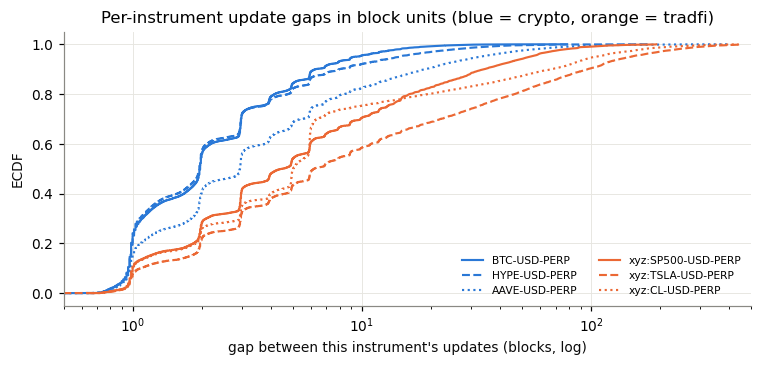

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for s in SYMS:
    g = inst[s].gap.dropna().values / bmean
    xs = np.sort(g); ys = np.arange(1, len(xs) + 1) / len(xs)
    ax.plot(xs, ys, color=C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI, lw=1.4,
            ls="-" if s in ("BTC-USD-PERP", "xyz:SP500-USD-PERP") else ("--" if s in ("HYPE-USD-PERP", "xyz:TSLA-USD-PERP") else ":"),
            label=s)
ax.set(xscale="log", xlim=(0.5, 500), xlabel="gap between this instrument's updates (blocks, log)", ylabel="ECDF",
       title="Per-instrument update gaps in block units (blue = crypto, orange = tradfi)")
ax.legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

## 4. Q2 — Are intervals independent?
**H0:** ρ(k) = 0. Three series, because raw gaps mix the clock with visibility:
* **raw gap** (union) — what you observe,
* **k = round(gap / mean block)** — the visibility process (how many blocks were skipped),
* **single-block gap** — the clock itself; non-single gaps are set to NaN and ACF uses pairwise-complete lags.

With n ≈ 200k, ±1.96/√n ≈ ±0.004: tiny ρ will be "significant". Read the magnitude.

In [11]:
def acf_nan(x, nlags):
    x = np.asarray(x, float); m = np.nanmean(x); x = x - m
    v = np.nanmean(x * x)
    out, ns = [], []
    for k in range(1, nlags + 1):
        a, b = x[:-k], x[k:]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.mean(a[ok] * b[ok]) / v); ns.append(ok.sum())
    return np.array(out), np.array(ns)

def lb_from_acf(r, n, lags):
    res = {}
    for L in lags:
        q = n * (n + 2) * np.sum(r[:L] ** 2 / (n - np.arange(1, L + 1)))
        res[L] = (q, stats.chi2.sf(q, L))
    return res

def q2_series(g):
    g = pd.Series(g).dropna().values   # reconnect gaps removed; series stitched (2 joins, negligible)
    single = np.where(g <= SINGLE_MAX, g, np.nan)
    return {"raw gap": g, "log raw gap": np.log(g), "k (skipped blocks)": np.round(g / bmean), "single-block gap": single}

rows, acfs = [], {}
for name, sser in q2_series(blk.gap).items():
    r, ns = acf_nan(sser, ACF_LAGS)
    lb = lb_from_acf(r, int(np.median(ns)), LB_LAGS)
    acfs[name] = r
    rows.append({"series": name, "n": int(np.sum(~np.isnan(sser))), **{f"rho({k})": r[k - 1] for k in (1, 2, 5, 10)},
                 **{f"LB({L}) p": lb[L][1] for L in LB_LAGS}})
q2_union = pd.DataFrame(rows).set_index("series")
print(f"±1.96/sqrt(n) band ≈ ±{1.96/np.sqrt(len(blk)):.4f}")
q2_union

±1.96/sqrt(n) band ≈ ±0.0044


,n,rho(1),rho(2),rho(5),rho(10),LB(1) p,LB(5) p,LB(10) p,LB(20) p
series,,,,,,,,,
raw gap,202358,0.1774,0.1793,0.1092,0.0704,0.0,0.0,0.0,0.0
log raw gap,202358,0.1452,0.2142,0.1154,0.0758,0.0,0.0,0.0,0.0
k (skipped blocks),202358,0.1696,0.1797,0.1068,0.0698,0.0,0.0,0.0,0.0
single-block gap,105613,-0.1997,0.0823,0.0292,0.0227,0.0,0.0,0.0,0.0


**Is the negative ρ(1) on single-block gaps just ms rounding?** Each timestamp is rounded to the ms; a rounding error
e_n enters gap n with + and gap n+1 with −, giving ρ(1) ≈ −Var(e)/Var(gap) with Var(e) = 1/12 ms². If the observed ρ(1)
is far below that, it's a real clock property: a block stamped late is followed by one stamped early (jitter around a
schedule / catch-up), which makes the next single-block interval partly predictable.

In [12]:
sg = q2_series(blk.gap)["single-block gap"]
v = np.nanvar(sg)
print(f"Var(single-block gap) = {v:.2f} ms^2 -> rounding-only rho(1) ≈ {-(1/12)/v:.4f}; observed {q2_union.loc['single-block gap','rho(1)']:.4f}")
a, b = sg[:-1], sg[1:]
ok = ~np.isnan(a) & ~np.isnan(b)
pairs_df = pd.DataFrame({"prev": a[ok], "next": b[ok]})
pairs_df["prev_bin"] = pd.cut(pairs_df.prev, [0, 55, 62, 65, 66, 67, 68, 69, 72, 80, 100])
pairs_df.groupby("prev_bin", observed=True).next.agg(["count", "median", "mean"]).round(2)

Var(single-block gap) = 80.71 ms^2 -> rounding-only rho(1) ≈ -0.0010; observed -0.1997


,count,median,mean
prev_bin,,,
"(0, 55]",4051,73.0,72.79
"(55, 62]",5678,70.0,71.41
"(62, 65]",6649,68.0,68.35
"(65, 66]",5538,67.0,67.85
"(66, 67]",6586,67.0,67.62
"(67, 68]",5226,67.0,67.13
"(68, 69]",3261,66.0,66.88
"(69, 72]",4184,66.0,66.57
"(72, 80]",5377,66.0,66.28


In [13]:
rows = []
for s in SYMS:
    for name, sser in q2_series(inst[s].gap).items():
        if name == "log raw gap":
            continue
        r, ns = acf_nan(sser, ACF_LAGS)
        lb = lb_from_acf(r, int(np.median(ns)), [10])
        rows.append({"symbol": s, "group": GROUP[s], "series": name, "n": int(np.sum(~np.isnan(sser))),
                     "rho(1)": r[0], "rho(5)": r[4], "LB(10) p": lb[10][1], "band": 1.96 / np.sqrt(max(np.median(ns), 1))})
q2_inst = pd.DataFrame(rows).pivot_table(index=["symbol", "group"], columns="series", values=["rho(1)", "rho(5)", "n"]).round(3)
q2_inst

n                                        rho(1)                                      rho(5)                         
series                    k (skipped blocks)   raw gap single-block gap k (skipped blocks) raw gap single-block gap k (skipped blocks) raw gap single-block gap
symbol             group                                                                                                                                       
AAVE-USD-PERP      crypto            48457.0   48457.0          12741.0              0.170   0.170           -0.172              0.045   0.046            0.030
BTC-USD-PERP       crypto           121428.0  121428.0          45810.0              0.211   0.212           -0.205              0.125   0.126            0.027
HYPE-USD-PERP      crypto            96638.0   96638.0          37739.0              0.231   0.232           -0.174              0.083   0.083            0.046
xyz:CL-USD-PERP    tradfi            18482.0   18482.0           3116.0              0.230   0.230           -0.184              0.141   0.141            0.044
xyz:SP500-USD-PERP tradfi            30915.0   30915.0           5322.0              0.202   0.202           -0.132              0.123   0.123            0.054
xyz:TSLA-USD-PERP  tradfi            11931.0   11931.0           1564.0              0.166   0.166           -0.310              0.053   0.053           -0.110

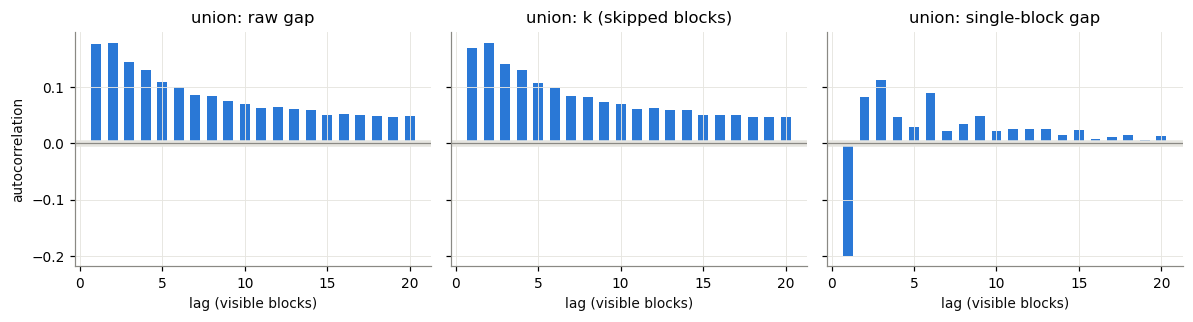

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
lags = np.arange(1, ACF_LAGS + 1)
for a, name in zip(ax, ["raw gap", "k (skipped blocks)", "single-block gap"]):
    a.bar(lags, acfs[name], width=0.6, color=C_CRYPTO)
    a.axhspan(-1.96 / np.sqrt(len(blk)), 1.96 / np.sqrt(len(blk)), color="#e6e5e0")
    a.axhline(0, color=C_MUTED, lw=0.8)
    a.set(title=f"union: {name}", xlabel="lag (visible blocks)")
ax[0].set_ylabel("autocorrelation")
plt.tight_layout(); plt.show()

## 5. Q3 — Does trading activity affect timing?
**H0:** next-gap distributions are equal after high- vs low-activity blocks (Mann–Whitney U).
Activity measures at block n (all backward-looking):
* `n_tr` — HL trades printed **in** block n (all 6 symbols),
* `hl_tr_1s` — HL trades in the 1 s up to and including block n,
* `bn_l1_1s` — Binance bookTicker updates (all 6 pairs) in the 1 s up to block n (Binance clock).

Two targets: **next raw gap** (visibility + clock) and **next gap, single-block only** (the clock). The second
conditions on the next gap being short — a descriptive test of the clock, not a usable forecast.
Also reported: the **contemporaneous** version (does a heavy block itself take longer?).

In [15]:
class Stream:
    """Sorted event times (ms) with O(log n) window counts / sums / as-of values. Windows are (a, b]."""
    def __init__(self, t, val=None, lmid=None):
        o = np.argsort(t, kind="stable")
        self.t = np.asarray(t)[o]
        self.cv = None if val is None else np.concatenate([[0.0], np.cumsum(np.asarray(val, float)[o])])
        self.lm = None if lmid is None else np.asarray(lmid, float)[o]
    def count(self, a, b):
        return np.searchsorted(self.t, b, "right") - np.searchsorted(self.t, a, "right")
    def sum(self, a, b):
        return self.cv[np.searchsorted(self.t, b, "right")] - self.cv[np.searchsorted(self.t, a, "right")]
    def lmid_at(self, q):
        i = np.searchsorted(self.t, q, "right") - 1
        return np.where(i >= 0, self.lm[np.clip(i, 0, None)], np.nan)
    def absret_bps(self, a, b):
        return np.abs(self.lmid_at(b) - self.lmid_at(a)) * 1e4

def make_streams(hl_l1, hl_tr, bn_l1, bn_tr):
    S = {"hl_tr": Stream(hl_tr.t.values, hl_tr.notional.values), "hl_l1": Stream(hl_l1.t.values)}
    for s in SYMS:
        b = PAIRS[s]
        S[f"bn_l1:{s}"] = Stream(bn_l1.t[bn_l1.symbol == b].values, lmid=bn_l1.lmid[bn_l1.symbol == b].values)
        S[f"bn_tr:{s}"] = Stream(bn_tr.t[bn_tr.symbol == b].values)
        S[f"hl_tr:{s}"] = Stream(hl_tr.t[hl_tr.symbol == s].values)
        S[f"hl_l1:{s}"] = Stream(hl_l1.t[hl_l1.symbol == s].values, lmid=hl_l1.lmid[hl_l1.symbol == s].values)
    S["bn_l1"] = Stream(bn_l1.t[bn_l1.symbol.isin(PAIRS.values())].values)
    S["bn_tr"] = Stream(bn_tr.t[bn_tr.symbol.isin(PAIRS.values())].values)
    return S

STREAMS = make_streams(hl_l1, hl_tr, bn_l1, bn_tr)

In [16]:
def mw_compare(act, y, label, act_cut):
    hi, lo = y[act > act_cut], y[act <= act_cut]
    hi, lo = hi[~np.isnan(hi)], lo[~np.isnan(lo)]
    if len(hi) < 30 or len(lo) < 30:
        return {"test": label, "n_hi": len(hi), "n_lo": len(lo)}
    u = stats.mannwhitneyu(hi, lo, alternative="two-sided")
    rng = np.random.default_rng(SEED)
    bs = [np.median(rng.choice(hi, len(hi))) - np.median(rng.choice(lo, len(lo))) for _ in range(300)]
    return {"test": label, "n_hi": len(hi), "n_lo": len(lo), "median_hi": np.median(hi), "median_lo": np.median(lo),
            "diff ms": np.median(hi) - np.median(lo), "diff CI lo": np.percentile(bs, 2.5), "diff CI hi": np.percentile(bs, 97.5),
            "AUC P(hi>lo)": u.statistic / (len(hi) * len(lo)), "MW p": u.pvalue}

def q3_table(bt, label_prefix=""):
    t = bt.t.values.astype(float)
    acts = {"n_tr (in block)": bt.n_tr.values.astype(float),
            "hl_tr_1s": STREAMS["hl_tr"].count(t - 1000, t).astype(float),
            "bn_l1_1s": STREAMS["bn_l1"].count(t - 1000, t).astype(float)}
    nxt = bt.gap.shift(-1).values
    cur = bt.gap.values
    tr = bt.t.values <= T_SPLIT
    rows = []
    for an, a in acts.items():
        cut = np.quantile(a[tr], ACT_HIGH_Q)
        if cut == 0:   # e.g. most blocks have no trade: "high" = any trade
            cut = 0.0
        for yn, y in [("next gap (raw)", nxt), ("next gap (single-block only)", np.where(nxt <= SINGLE_MAX, nxt, np.nan)),
                      ("same-block gap (single-block only)", np.where(cur <= SINGLE_MAX, cur, np.nan))]:
            r = mw_compare(a, y, f"{label_prefix}{an} → {yn}", cut)
            r["hi cut"] = cut
            rows.append(r)
            log_trial(q="Q3", test=r["test"])
    return pd.DataFrame(rows).set_index("test")

q3_union = q3_table(blk)
q3_union

,n_hi,n_lo,median_hi,median_lo,diff ms,diff CI lo,diff CI hi,AUC P(hi>lo),MW p,hi cut
test,,,,,,,,,,
n_tr (in block) → next gap (raw),19408,182950,84.0,90.0,-6.0,-7.0,-4.0,0.4855,2.8393e-11,1.0
n_tr (in block) → next gap (single-block only),10470,95143,67.0,67.0,0.0,0.0,0.0,0.4983,5.6933e-01,1.0
n_tr (in block) → same-block gap (single-block only),9717,95896,68.0,67.0,1.0,0.0,1.0,0.5148,1.3869e-06,1.0
hl_tr_1s → next gap (raw),39296,163062,76.0,101.0,-25.0,-27.0,-23.0,0.4136,0.0000e+00,7.0
hl_tr_1s → next gap (single-block only),24349,81264,67.0,67.0,0.0,0.0,0.0,0.4942,6.2338e-03,7.0
hl_tr_1s → same-block gap (single-block only),24915,80698,67.0,67.0,0.0,0.0,0.0,0.4924,2.9094e-04,7.0
bn_l1_1s → next gap (raw),46501,155857,75.0,108.0,-33.0,-35.0,-32.0,0.3900,0.0000e+00,333.0
bn_l1_1s → next gap (single-block only),29756,75857,67.0,67.0,0.0,0.0,0.0,0.4839,3.2121e-16,333.0
bn_l1_1s → same-block gap (single-block only),29473,76140,67.0,67.0,0.0,0.0,0.0,0.4847,1.0009e-14,333.0


In [17]:
rows = []
for s in SYMS:
    d = q3_table(inst[s], f"{s} | ")
    d["symbol"], d["group"] = s, GROUP[s]
    rows.append(d)
q3_inst = pd.concat(rows)
q3_inst[["n_hi", "n_lo", "median_hi", "median_lo", "diff ms", "diff CI lo", "diff CI hi", "AUC P(hi>lo)", "MW p"]]

,n_hi,n_lo,median_hi,median_lo,diff ms,diff CI lo,diff CI hi,AUC P(hi>lo),MW p
test,,,,,,,,,
BTC-USD-PERP | n_tr (in block) → next gap (raw),21276,100152,136.0,133.0,3.0,3.0000,4.000,0.5469,7.1482e-103
BTC-USD-PERP | n_tr (in block) → next gap (single-block only),7245,38565,67.0,67.0,0.0,0.0000,1.000,0.5067,6.8149e-02
BTC-USD-PERP | n_tr (in block) → same-block gap (single-block only),6703,39107,67.0,67.0,0.0,0.0000,0.000,0.5018,6.3873e-01
BTC-USD-PERP | hl_tr_1s → next gap (raw),25854,95574,101.0,135.0,-34.0,-38.0000,-31.475,0.3885,0.0000e+00
BTC-USD-PERP | hl_tr_1s → next gap (single-block only),12842,32968,67.0,67.0,0.0,0.0000,0.000,0.4954,1.2765e-01
BTC-USD-PERP | hl_tr_1s → same-block gap (single-block only),13065,32745,67.0,67.0,0.0,0.0000,0.000,0.4942,5.1220e-02
BTC-USD-PERP | bn_l1_1s → next gap (raw),28234,93194,86.0,136.0,-50.0,-52.0000,-49.000,0.3333,0.0000e+00
BTC-USD-PERP | bn_l1_1s → next gap (single-block only),15350,30460,67.0,67.0,0.0,0.0000,0.000,0.4815,8.2404e-11
BTC-USD-PERP | bn_l1_1s → same-block gap (single-block only),15139,30671,67.0,67.0,0.0,0.0000,0.000,0.4821,3.8825e-10


## 6. Features + truncation test
One function builds every forecasting feature for a set of query blocks. Everything is a function of data with
time ≤ the query block's `t` (HL clock for HL, Binance clock for Binance). The truncation test recomputes features
with all data after a cut removed and checks that features at or before the cut are unchanged.

In [18]:
def build_features(bt, streams, sym=None):
    """Features at block n in exchange time (t_n). bt: block table (union or one instrument) with t, gap, n_tr, notional, n_l1."""
    t = bt.t.values.astype(float)
    tb = t
    g = bt.gap.values
    F = pd.DataFrame(index=bt.index)
    lg = np.log(pd.Series(g, index=bt.index))
    for j in range(10):
        F[f"lg{j}"] = lg.shift(j)                       # lg0 = log gap that ended at block n (known at t_n)
    gs = pd.Series(g, index=bt.index)
    F["med20"] = gs.rolling(20, min_periods=5).median()   # backward rolling, includes current gap only
    F["med200"] = gs.rolling(200, min_periods=20).median()
    F["single_share50"] = (gs <= SINGLE_MAX).astype(float).where(gs.notna()).rolling(50, min_periods=10).mean()
    # HL activity
    F["n_tr_blk"] = bt.n_tr.values
    F["lnot_blk"] = np.log1p(bt.notional.values)
    F["n_l1_blk"] = bt.n_l1.values
    if "n_sym" in bt:
        F["n_sym_blk"] = bt.n_sym.values
        F["upd_crypto_blk"] = bt.upd_crypto.values
        F["upd_tradfi_blk"] = bt.upd_tradfi.values
    F["hl_tr_1s"] = streams["hl_tr"].count(t - 1000, t)
    F["hl_lnot_1s"] = np.log1p(streams["hl_tr"].sum(t - 1000, t))
    F["hl_l1_1s"] = streams["hl_l1"].count(t - 1000, t)
    hl_cols = list(F.columns)
    # Binance activity (Binance clock; §8 replaces these with latency-aware versions)
    pairs = [sym] if sym else SYMS
    for w in (100, 1000):
        F[f"bn_l1_{w}"] = sum(streams[f"bn_l1:{s}"].count(tb - w, tb) for s in pairs)
        F[f"bn_tr_{w}"] = sum(streams[f"bn_tr:{s}"].count(tb - w, tb) for s in pairs)
        if sym:
            F[f"bn_absret_{w}"] = streams[f"bn_l1:{sym}"].absret_bps(tb - w, tb)
        else:
            for grp in ("crypto", "tradfi"):
                F[f"bn_absret_{w}_{grp}"] = np.nansum([streams[f"bn_l1:{s}"].absret_bps(tb - w, tb) for s in SYMS if GROUP[s] == grp], axis=0)
    bn_cols = [c for c in F.columns if c not in hl_cols]
    lag_cols = [c for c in hl_cols if c.startswith("lg") or c.startswith("med") or c.startswith("single")]
    return F, {"F1 lags": lag_cols, "F2 +HL activity": hl_cols, "F3 +Binance": hl_cols + bn_cols}

def truncation_test(bt, sym=None, n_cuts=3):
    full, _ = build_features(bt, STREAMS, sym)
    for frac in np.linspace(0.3, 0.8, n_cuts):
        cut = bt.t.quantile(frac)
        S_cut = make_streams(hl_l1[hl_l1.t <= cut], hl_tr[hl_tr.t <= cut], bn_l1[bn_l1.t <= cut], bn_tr[bn_tr.t <= cut])
        part, _ = build_features(bt[bt.t <= cut], S_cut, sym)
        a, b = full.loc[part.index].values, part.values
        ok = np.allclose(a, b, equal_nan=True)
        assert ok, f"LEAK: features at/before {cut} change when future data is removed ({np.argwhere(~np.isclose(a, b, equal_nan=True))[:5]})"
    return True

print("truncation test union:", truncation_test(blk))
print("truncation test BTC:", truncation_test(inst["BTC-USD-PERP"], "BTC-USD-PERP"))
print("truncation test xyz:TSLA:", truncation_test(inst["xyz:TSLA-USD-PERP"], "xyz:TSLA-USD-PERP"))

truncation test union: True


truncation test BTC: True


truncation test xyz:TSLA: True


## 7. Q4 — Can previous intervals predict the next? (Wald test)
OLS of log next gap on 10 lags of log gap (+ constant), Newey–West HAC. **H0:** all lag coefficients = 0.
Also: the same with HL activity added, testing whether activity adds anything given lags. Fit on train; OOS R² on test.

In [19]:
def q4(bt, sym=None, label="union"):
    F, sets = build_features(bt, STREAMS, sym)
    y = np.log(bt.gap.shift(-1))
    d = pd.concat([F, y.rename("y"), bt.t], axis=1).dropna()
    tr = d.t <= T_SPLIT
    out = {}
    lag_cols = [f"lg{j}" for j in range(10)]
    act_cols = ["n_tr_blk", "lnot_blk", "hl_tr_1s", "hl_l1_1s"]
    for nm, cols, test_cols in [("lags", lag_cols, lag_cols), ("lags+activity", lag_cols + act_cols, act_cols)]:
        X = sm.add_constant(d.loc[tr, cols])
        m = sm.OLS(d.loc[tr, "y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        R = np.zeros((len(test_cols), X.shape[1]))
        for i, c in enumerate(test_cols):
            R[i, list(X.columns).index(c)] = 1
        wt = m.wald_test(R, scalar=True)
        yhat = m.predict(sm.add_constant(d.loc[~tr, cols], has_constant="add"))
        yt = d.loc[~tr, "y"]
        r2_oos = 1 - np.sum((yt - yhat) ** 2) / np.sum((yt - d.loc[tr, "y"].mean()) ** 2)
        out[nm] = {"set": label, "model": nm, "tested": "lags" if nm == "lags" else "activity | lags",
                   "Wald F": float(wt.statistic), "Wald p": float(wt.pvalue), "R2 train": m.rsquared, "R2 OOS": r2_oos,
                   "coef lg0": m.params.get("lg0"), "n_train": int(tr.sum())}
        log_trial(q="Q4", set=label, model=nm)
    return list(out.values())

q4_tab = pd.DataFrame(q4(blk) + sum([q4(inst[s], s, s) for s in SYMS], [])).set_index(["set", "model"])
q4_tab

tested      Wald F       Wald p  R2 train  R2 OOS  coef lg0  n_train
set                model                                                                                       
union              lags                      lags  10342.6361   0.0000e+00    0.0787  0.0931    0.0843   121386
                   lags+activity  activity | lags   1779.4269   0.0000e+00    0.0923  0.1058    0.0455   121386
BTC-USD-PERP       lags                      lags   8511.7986   0.0000e+00    0.1079  0.1568    0.1469    70598
                   lags+activity  activity | lags    530.0081  2.1632e-113    0.1162  0.1649    0.1245    70598
HYPE-USD-PERP      lags                      lags  11109.3394   0.0000e+00    0.1669  0.1464    0.2571    55310
                   lags+activity  activity | lags    292.2788   5.0142e-62    0.1748  0.1529    0.2361    55310
AAVE-USD-PERP      lags                      lags   2253.4726   0.0000e+00    0.0840  0.1122    0.2271    26257
                   lags+activity  activity | lags    147.2301   7.9839e-31    0.0877  0.1229    0.2090    26257
xyz:SP500-USD-PERP lags                      lags   2284.0881   0.0000e+00    0.1188  0.2229    0.2377    20779
                   lags+activity  activity | lags    390.6134   2.9669e-83    0.1499  0.2480    0.2107    20779
xyz:TSLA-USD-PERP  lags                      lags    647.4204  1.2029e-132    0.0822  0.0805    0.2192     6539
                   lags+activity  activity | lags     78.2568   4.0757e-16    0.1006  0.1128    0.1822     6539
xyz:CL-USD-PERP    lags                      lags   2901.6321   0.0000e+00    0.2127  0.1883    0.3336    10907
                   lags+activity  activity | lags     60.3222   2.4821e-12    0.2186  0.1960    0.3138    10907

## 8. Q5 — Can we forecast the next block within an interval? (out-of-sample, with latency)
The target is still **exchange block time**. The forecast is made at the moment we *know* block n:
`q_n = t_n + latency` (made monotone, so we never act on block n before every earlier block is known).
* **Target** y_n = (exchange time of the first visible block after q_n) − q_n. With ~0 latency this is the next gap;
  with real latency it's the residual wait from the moment we find out.
* **HL features** = the §6 exchange-time features of block n (all built from blocks ≤ n, so all known at q_n),
  plus `staleness` = q_n − t_n.
* **Binance features** use Binance's own latency: only Binance events with `t + latency ≤ q_n` count.

Nested sets, quantile gradient boosting (q10/q50/q90), fit on train and scored on test:
**F0** unconditional train quantiles → **F1** gap lags + staleness → **F2** + HL activity → **F3** + Binance.
Metrics: pinball skill vs F0 (95% block-bootstrap CI), gain over the previous set, 80% coverage, width, MAE of the median.

In [20]:
def latency_view(scen, seed=SEED):
    """Known times under a latency scenario: per union block (prefix-max) + Binance streams keyed on known time."""
    rng = np.random.default_rng(seed)
    t = blk.t.values.astype(float)
    if scen["kind"] == "normal":
        mu, sd = scen["hl"]
        known = t + np.clip(rng.normal(mu, sd, len(t)), 0, None)
        bmu, bsd = scen["bn"]
        bn_known_l1 = bn_l1.t.values + np.clip(rng.normal(bmu, bsd, len(bn_l1)), 0, None)
        bn_known_tr = bn_tr.t.values + np.clip(rng.normal(bmu, bsd, len(bn_tr)), 0, None)
    else:
        known = blk_recv.loc[blk.t].values
        bn_known_l1, bn_known_tr = bn_l1.recv.values, bn_tr.recv.values
    K = pd.Series(np.maximum.accumulate(known), index=blk.t.values)   # block n usable only once blocks <= n are all known
    S = {}
    for s in SYMS:
        m1, m2 = (bn_l1.symbol == PAIRS[s]).values, (bn_tr.symbol == PAIRS[s]).values
        S[f"bn_l1:{s}"] = Stream(bn_known_l1[m1], lmid=bn_l1.lmid.values[m1])
        S[f"bn_tr:{s}"] = Stream(bn_known_tr[m2])
    return K, S

def lat_features(bt, sym, K, S_bn):
    F, sets = build_features(bt, STREAMS, sym)
    bn_cols = [c for c in sets["F3 +Binance"] if c not in sets["F2 +HL activity"]]
    q = K.loc[bt.t.values].values
    F["staleness"] = q - bt.t.values
    pairs = [sym] if sym else SYMS
    for w in (100, 1000):    # recompute Binance features on known time at q (replaces the exchange-time versions)
        F[f"bn_l1_{w}"] = sum(S_bn[f"bn_l1:{s}"].count(q - w, q) for s in pairs)
        F[f"bn_tr_{w}"] = sum(S_bn[f"bn_tr:{s}"].count(q - w, q) for s in pairs)
        if sym:
            F[f"bn_absret_{w}"] = S_bn[f"bn_l1:{sym}"].absret_bps(q - w, q)
        else:
            for grp in ("crypto", "tradfi"):
                F[f"bn_absret_{w}_{grp}"] = np.nansum([S_bn[f"bn_l1:{s}"].absret_bps(q - w, q) for s in SYMS if GROUP[s] == grp], axis=0)
    sets = {"F1 lags": sets["F1 lags"] + ["staleness"], "F2 +HL activity": sets["F2 +HL activity"] + ["staleness"],
            "F3 +Binance": sets["F2 +HL activity"] + ["staleness"] + bn_cols}
    # target: first visible block of this table strictly after q, in exchange time, same connection
    tt = bt.t.values
    j = np.searchsorted(tt, q, "right")
    ok = j < len(tt)
    jj = np.clip(j, 0, len(tt) - 1)
    ok &= bt.ordinal.values[jj] == bt.ordinal.values
    y = np.where(ok, tt[jj] - q, np.nan)
    return F, sets, pd.Series(y, index=bt.index), q

def lat_truncation_test(scen_name, sym=None):
    """Binance known-time features at q must not change when every event known after a cut is deleted."""
    K, S_full = latency_view(LATENCY_SCENARIOS[scen_name])
    bt = blk if sym is None else inst[sym]
    F_full, _, _, q = lat_features(bt, sym, K, S_full)
    for frac in (0.4, 0.7):
        cut = np.quantile(q, frac)
        S_cut = {k: Stream(v.t[v.t <= cut], lmid=None if v.lm is None else v.lm[v.t <= cut]) for k, v in S_full.items()}
        F_cut, _, _, _ = lat_features(bt, sym, K, S_cut)
        keep = q <= cut
        a, b = F_full.loc[keep].values, F_cut.loc[keep].values
        assert np.allclose(a, b, equal_nan=True), f"LEAK in latency features ({scen_name}, {sym})"
        assert (K.loc[bt.t.values[keep]].values <= cut).all()
    return True

for nm in LATENCY_SCENARIOS:
    print(f"latency truncation test [{nm}] union:", lat_truncation_test(nm), "| HYPE:", lat_truncation_test(nm, "HYPE-USD-PERP"))

latency truncation test [N(0.50, 0.05) ms] union: True | HYPE: True


latency truncation test [measured ts_recv] union: True | HYPE: True


In [21]:
def pinball(y, q, tau):
    d = y - q
    return np.maximum(tau * d, (tau - 1) * d)

def block_boot_ci(diff, reps=BOOT_REPS, block=BOOT_BLOCK, seed=SEED):
    n = len(diff); rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block)); starts = rng.integers(0, max(n - block, 1), size=(reps, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(reps, -1)[:, :n]
    m = diff[idx].mean(1)
    return np.percentile(m, [2.5, 97.5])

def q5(bt, sym, label, scen_name, K, S_bn):
    F, sets, y, q = lat_features(bt, sym, K, S_bn)
    d = pd.concat([F, y.rename("y"), bt.t], axis=1)
    d = d[d.y.notna() & d.lg0.notna()]
    tr = (d.t <= T_SPLIT).values
    ytr, yte = d.y.values[tr], d.y.values[~tr]
    preds = {"F0 unconditional": np.tile(np.quantile(ytr, QUANTILES), (len(yte), 1))}
    for nm, cols in sets.items():
        P = []
        for tau in QUANTILES:
            m = HistGradientBoostingRegressor(loss="quantile", quantile=tau, **HGB_KW).fit(d.loc[tr, cols], ytr)
            P.append(m.predict(d.loc[~tr, cols]))
        preds[nm] = np.sort(np.column_stack(P), axis=1)   # no quantile crossing
        log_trial(q="Q5", set=label, model=nm, latency=scen_name)
    loss = {k: np.mean([pinball(yte, p[:, i], tau) for i, tau in enumerate(QUANTILES)], axis=0) for k, p in preds.items()}
    rows, names = [], list(preds)
    ref = loss["F0 unconditional"]
    for i, k in enumerate(names):
        p = preds[k]
        prev = loss[names[i - 1]] if i > 0 else None
        ci0 = block_boot_ci((ref - loss[k]) / ref.mean()) if i > 0 else (np.nan, np.nan)
        cip = block_boot_ci((prev - loss[k]) / ref.mean()) if i > 1 else (np.nan, np.nan)
        rows.append({"latency": scen_name, "set": label, "features": k, "group": GROUP.get(sym, "all"), "n_test": len(yte),
                     "median staleness ms": np.median(F.staleness.loc[d.index[~tr]]), "median target ms": np.median(yte),
                     "pinball": loss[k].mean(), "skill vs F0": 1 - loss[k].mean() / ref.mean(),
                     "skill CI lo": ci0[0], "skill CI hi": ci0[1],
                     "gain vs prev set": (prev.mean() - loss[k].mean()) / ref.mean() if prev is not None else np.nan,
                     "gain CI lo": cip[0], "gain CI hi": cip[1],
                     "coverage 80%": np.mean((yte >= p[:, 0]) & (yte <= p[:, 2])),
                     "median width ms": np.median(p[:, 2] - p[:, 0]), "MAE median ms": np.mean(np.abs(yte - p[:, 1]))})
    return pd.DataFrame(rows)

q5_rows = []
for scen_name, scen in LATENCY_SCENARIOS.items():
    K, S_bn = latency_view(scen)
    for s in [None] + SYMS:
        q5_rows.append(q5(blk if s is None else inst[s], s, s or "union", scen_name, K, S_bn))
q5_all = pd.concat(q5_rows)
q5_all.set_index(["latency", "set", "features"])[["n_test", "median staleness ms", "median target ms", "skill vs F0",
    "skill CI lo", "skill CI hi", "gain vs prev set", "gain CI lo", "gain CI hi", "coverage 80%", "median width ms", "MAE median ms"]]

C:\Users\markp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\markp\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\markp\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

n_test  median staleness ms  median target ms  skill vs F0  skill CI lo  skill CI hi  gain vs prev set  gain CI lo  gain CI hi  coverage 80%  \
latency          set                features                                                                                                                                                         
N(0.50, 0.05) ms union              F0 unconditional   80941               0.5002           83.5554       0.0000          NaN          NaN               NaN         NaN         NaN        0.8044   
                                    F1 lags            80941               0.5002           83.5554       0.1139       0.1082       0.1196            0.1139         NaN         NaN        0.7966   
                                    F2 +HL activity    80941               0.5002           83.5554       0.1277       0.1221       0.1335            0.0138      0.0122      0.0152        0.7905   
                                    F3 +Binance        80941               0.5002           83.5554       0.1412       0.1343       0.1477            0.0135      0.0116      0.0153        0.7906   
                 BTC-USD-PERP       F0 unconditional   50799               0.5000          130.5396       0.0000          NaN          NaN               NaN         NaN         NaN        0.8018   
                                    F1 lags            50799               0.5000          130.5396       0.1080       0.0961       0.1195            0.1080         NaN         NaN        0.7889   
                                    F2 +HL activity    50799               0.5000          130.5396       0.1176       0.1062       0.1291            0.0096      0.0077      0.0113        0.7847   
                                    F3 +Binance        50799               0.5000          130.5396       0.1341       0.1222       0.1457            0.0166      0.0147      0.0186        0.7819   
                 HYPE-USD-PERP      F0 unconditional   41297               0.5005          130.5300       0.0000          NaN          NaN               NaN         NaN         NaN        0.8038   
                                    F1 lags            41297               0.5005          130.5300       0.1137       0.1051       0.1230            0.1137         NaN         NaN        0.7859   
                                    F2 +HL activity    41297               0.5005          130.5300       0.1228       0.1131       0.1334            0.0091      0.0068      0.0116        0.7839   
                                    F3 +Binance        41297               0.5005          130.5300       0.1686       0.1569       0.1813            0.0458      0.0414      0.0498        0.7828   
                 AAVE-USD-PERP      F0 unconditional   22169               0.5005          189.4800       0.0000          NaN          NaN               NaN         NaN         NaN        0.8170   
                                    F1 lags            22169               0.5005          189.4800       0.0946       0.0817       0.1103            0.0946         NaN         NaN        0.7828   
                                    F2 +HL activity    22169               0.5005          189.4800       0.0956       0.0826       0.1117            0.0010     -0.0012      0.0031        0.7812   
                                    F3 +Binance        22169               0.5005          189.4800       0.1597       0.1459       0.1749            0.0641      0.0578      0.0704        0.7761   
                 xyz:SP500-USD-PERP F0 unconditional   10105               0.5012          285.4211       0.0000          NaN          NaN               NaN         NaN         NaN        0.7478   
                                    F1 lags            10105               0.5012          285.4211       0.1081       0.0887       0.1350            0.1081         NaN         NaN        0.7353   
                                    F2 +HL activity    10105               0.5012          285

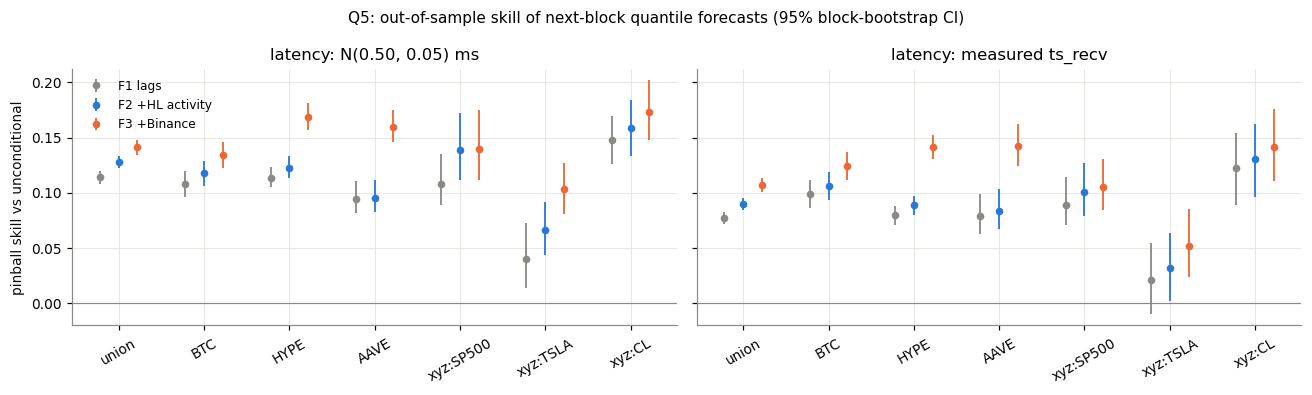

In [22]:
fig, axes = plt.subplots(1, len(LATENCY_SCENARIOS), figsize=(12, 3.6), sharey=True)
sets_order = ["F1 lags", "F2 +HL activity", "F3 +Binance"]
labels = ["union"] + SYMS
xs = np.arange(len(labels))
for ax, scen_name in zip(np.atleast_1d(axes), LATENCY_SCENARIOS):
    for j, fs in enumerate(sets_order):
        sub = q5_all[(q5_all.features == fs) & (q5_all.latency == scen_name)].set_index("set").loc[labels]
        err = np.vstack([sub["skill vs F0"] - sub["skill CI lo"], sub["skill CI hi"] - sub["skill vs F0"]])
        ax.errorbar(xs + (j - 1) * 0.22, sub["skill vs F0"], yerr=err, fmt="o", ms=4, lw=1.2,
                    color=[C_MUTED, C_CRYPTO, C_TRADFI][j], label=fs, capsize=0)
    ax.axhline(0, color=C_MUTED, lw=0.8)
    ax.set_xticks(xs, [l.replace("-USD-PERP", "") for l in labels], rotation=30)
    ax.set(title=f"latency: {scen_name}")
np.atleast_1d(axes)[0].set_ylabel("pinball skill vs unconditional")
np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8)
fig.suptitle("Q5: out-of-sample skill of next-block quantile forecasts (95% block-bootstrap CI)", fontsize=10)
plt.tight_layout(); plt.show()

## 9. Binance inside HL's gaps
### 9.1 Timing: does Binance activity *during* the gap move the hazard of the next HL block?
Discrete-time hazard: for every gap, checkpoints at t = 0, 10, …, < min(gap, 600) ms after block n. Event = the next
visible block lands in (t, t+10]. Model A uses only info at block n + elapsed t; model B adds Binance activity since
block n and in the last 20 ms (Binance clock). Scored by test log-loss; ΔLL CI by block bootstrap over gaps.

In [23]:
def hazard_frame(bt, sym=None):
    F, _ = build_features(bt, STREAMS, sym)
    base_cols = ["lg0", "lg1", "med20", "med200", "n_tr_blk", "hl_tr_1s", "hl_l1_1s"] + (["n_sym_blk"] if sym is None else [])
    G = bt.gap.shift(-1).values
    ok = ~np.isnan(G) & F.lg0.notna().values
    t0, G, Fb = bt.t.values[ok].astype(float), G[ok], F.loc[ok, base_cols].values
    nstep = np.minimum(np.ceil(G / HAZ_STEP), HAZ_TMAX // HAZ_STEP).astype(int)
    gi = np.repeat(np.arange(len(G)), nstep)
    el = np.concatenate([np.arange(n) * HAZ_STEP for n in nstep]).astype(float)
    ev_ = (G[gi] > el) & (G[gi] <= el + HAZ_STEP)
    q = t0[gi] + el
    qb, t0b = q, t0[gi]
    pairs = [sym] if sym else SYMS
    X = pd.DataFrame(Fb[gi], columns=base_cols)
    X["elapsed"] = el
    A_cols = list(X.columns)
    X["bn_l1_since"] = sum(STREAMS[f"bn_l1:{s}"].count(t0b, qb) for s in pairs)
    X["bn_l1_last20"] = sum(STREAMS[f"bn_l1:{s}"].count(qb - 20, qb) for s in pairs)
    X["bn_tr_since"] = sum(STREAMS[f"bn_tr:{s}"].count(t0b, qb) for s in pairs)
    X["bn_absret_since"] = np.nansum([STREAMS[f"bn_l1:{s}"].absret_bps(t0b, qb) for s in pairs], axis=0)
    return X, ev_.astype(int), gi, t0[gi], A_cols

def hazard_eval(bt, sym=None, label="union"):
    X, yv, gi, tq, A_cols = hazard_frame(bt, sym)
    tr = tq <= T_SPLIT
    out = {}
    for nm, cols in [("A: HL info + elapsed", A_cols), ("B: + Binance in gap", list(X.columns))]:
        m = HistGradientBoostingClassifier(**HGB_KW).fit(X.loc[tr, cols], yv[tr])
        p = np.clip(m.predict_proba(X.loc[~tr, cols])[:, 1], 1e-6, 1 - 1e-6)
        out[nm] = -(yv[~tr] * np.log(p) + (1 - yv[~tr]) * np.log(1 - p))
        log_trial(q="Q-hazard", set=label, model=nm)
    d = out["A: HL info + elapsed"] - out["B: + Binance in gap"]
    per_gap = pd.Series(d).groupby(gi[~tr]).sum().values     # bootstrap over gaps, in time order
    ci = block_boot_ci(per_gap) / (len(d) / len(per_gap))
    return {"set": label, "group": GROUP.get(sym, "all"), "rows_test": len(d),
            "LL A": out["A: HL info + elapsed"].mean(), "LL B": out["B: + Binance in gap"].mean(),
            "ΔLL (A−B) per row": d.mean(), "CI lo": ci[0], "CI hi": ci[1],
            "rel. improvement": d.mean() / out["A: HL info + elapsed"].mean()}

haz = pd.DataFrame([hazard_eval(blk if s is None else inst[s], s, s or "union")
                    for s in [None] + SYMS]).set_index("set")
haz

,group,rows_test,LL A,LL B,ΔLL (A−B) per row,CI lo,CI hi,rel. improvement
set,,,,,,,,
union,all,1006927,0.1770,0.1769,7.5283e-05,1.0403e-05,1.3768e-04,0.0004
BTC-USD-PERP,crypto,915998,0.1520,0.1519,1.2633e-04,4.6579e-05,2.2099e-04,0.0008
HYPE-USD-PERP,crypto,786364,0.1422,0.1416,6.3629e-04,5.6517e-04,7.2153e-04,0.0045
AAVE-USD-PERP,crypto,568954,0.1157,0.1144,1.3443e-03,1.1868e-03,1.5035e-03,0.0116
xyz:SP500-USD-PERP,tradfi,341653,0.0767,0.0767,-1.9657e-05,-8.6316e-05,5.6569e-05,-0.0003
xyz:TSLA-USD-PERP,tradfi,200678,0.0695,0.0683,1.1963e-03,9.9819e-04,1.4423e-03,0.0172
xyz:CL-USD-PERP,tradfi,262934,0.0787,0.0784,2.7886e-04,9.1321e-05,4.7072e-04,0.0035


### 9.2 Clock vs visibility
A Binance gain in 9.1 can come from two very different things:
* **visibility** — Binance moves → HL quotes on that instrument reprice → the next block becomes *visible* sooner,
* **clock** — Binance activity actually changes how long HL takes to commit a block.

Clock test: among next gaps that are single-block, is gap length related to Binance activity in the first 40 ms
after block n (before the earliest plausible block end)? Spearman ρ with bootstrap CI. Descriptive (conditions on the
next gap being short).

In [24]:
rows = []
for s_ in [None] + SYMS:
    bt = blk if s_ is None else inst[s_]
    G = bt.gap.shift(-1).values; t = bt.t.values.astype(float)
    m = (G <= SINGLE_MAX) & ~np.isnan(G)
    pairs = [s_] if s_ else SYMS
    x = sum(STREAMS[f"bn_l1:{s}"].count(t[m], t[m] + 40) for s in pairs).astype(float)
    r = stats.spearmanr(x, G[m])
    rng = np.random.default_rng(SEED)
    bs = [stats.spearmanr(x[i], G[m][i]).statistic for i in (rng.integers(0, m.sum(), m.sum()) for _ in range(200))]
    rows.append({"set": s_ or "union", "group": GROUP.get(s_, "all"), "n single-block next gaps": int(m.sum()),
                 "spearman(bn updates in first 40ms, gap)": r.statistic, "CI lo": np.percentile(bs, 2.5),
                 "CI hi": np.percentile(bs, 97.5), "p": r.pvalue})
clock_test = pd.DataFrame(rows).set_index("set")
clock_test

,group,n single-block next gaps,"spearman(bn updates in first 40ms, gap)",CI lo,CI hi,p
set,,,,,,
union,all,105613,0.0009,-0.0053,0.0064,0.7598
BTC-USD-PERP,crypto,45810,-0.0023,-0.0114,0.0061,0.6231
HYPE-USD-PERP,crypto,37739,0.0042,-0.0047,0.0151,0.4092
AAVE-USD-PERP,crypto,12741,0.0004,-0.0186,0.0172,0.9595
xyz:SP500-USD-PERP,tradfi,5322,-0.0287,-0.0548,-0.0023,0.0361
xyz:TSLA-USD-PERP,tradfi,1564,-0.0329,-0.0824,0.0147,0.1941
xyz:CL-USD-PERP,tradfi,3116,-0.0129,-0.0507,0.0171,0.4726


### 9.3 Price: does Binance inside the gap tell you HL's next move?
For each instrument, consecutive HL l1 updates a → b. ΔHL = HL log-mid change (bps).
* **Lead profile:** corr(ΔHL, Binance return over (t_a+s, t_b+s]) across shifts s. A peak at s < 0 means Binance
  moves before HL; the location also absorbs any clock offset.
* **Within-gap predictive:** Binance return over (t_a, t_b − δ] (known before block b lands, if gap > δ) → ΔHL.
  OLS slope fit on train, OOS R² on test vs a zero forecast, and sign hit-rate where both are non-zero.

In [25]:
lead_prof, lead_rows = {}, []
for s in SYMS:
    h = hl_l1[hl_l1.symbol == s].sort_values("t").drop_duplicates("t", keep="last")
    h = h[h.conn_ordinal == h.conn_ordinal.shift()]   # pairs within one connection
    ta = h.t.shift().values; tb = h.t.values.astype(float); dhl = (h.lmid.diff().values) * 1e4
    ok = ~np.isnan(ta) & ~np.isnan(dhl)
    ta, tb, dhl = ta[ok], tb[ok], dhl[ok]
    bn = STREAMS[f"bn_l1:{s}"]
    prof = []
    for sh in LEAD_SHIFTS:
        r = (bn.lmid_at(tb + sh) - bn.lmid_at(ta + sh)) * 1e4
        v = ~np.isnan(r)
        prof.append(np.corrcoef(dhl[v], r[v])[0, 1])
    lead_prof[s] = np.array(prof)
    tr = tb <= T_SPLIT
    for dl in WITHIN_DELTAS:
        r = (bn.lmid_at(tb - dl) - bn.lmid_at(ta)) * 1e4
        v = ~np.isnan(r) & ((tb - ta) > dl)
        b = np.sum(r[v & tr] * dhl[v & tr]) / np.sum(r[v & tr] ** 2)   # no-intercept OLS slope (train)
        te = v & ~tr
        r2 = 1 - np.sum((dhl[te] - b * r[te]) ** 2) / np.sum(dhl[te] ** 2)
        nz = te & (dhl != 0) & (r != 0)
        lead_rows.append({"symbol": s, "group": GROUP[s], "delta ms": dl, "n_test": int(te.sum()),
                          "share HL mid moved": np.mean(dhl[te] != 0), "slope (train)": b, "OOS R2": r2,
                          "sign hit-rate": np.mean(np.sign(dhl[nz]) == np.sign(r[nz])), "n sign": int(nz.sum())})
        log_trial(q="Q-lead", set=s, model=f"within-gap delta={dl}")
lead_tab = pd.DataFrame(lead_rows).set_index(["symbol", "delta ms"])
peak = pd.DataFrame({s: {"peak shift ms": LEAD_SHIFTS[np.nanargmax(p)], "peak corr": np.nanmax(p), "corr at 0": p[LEAD_SHIFTS == 0][0]}
                     for s, p in lead_prof.items()}).T
display(peak)
lead_tab

,peak shift ms,peak corr,corr at 0
BTC-USD-PERP,-480.0,0.3697,0.0246
HYPE-USD-PERP,-450.0,0.2495,0.1751
AAVE-USD-PERP,-180.0,0.4176,0.2982
xyz:SP500-USD-PERP,260.0,0.0962,0.0239
xyz:TSLA-USD-PERP,-140.0,0.3959,0.3541
xyz:CL-USD-PERP,-200.0,0.4627,0.2842


group  n_test  share HL mid moved  slope (train)      OOS R2  sign hit-rate  n sign
symbol             delta ms                                                                                      
BTC-USD-PERP       10        crypto   50749              0.0353         0.0274  1.3238e-05         0.8532     109
                   30        crypto   50748              0.0353         0.0262 -6.5616e-05         0.8667      90
                   60        crypto   48314              0.0335         0.0222 -4.5248e-06         0.8361      61
HYPE-USD-PERP      10        crypto   41266              0.2751         0.1641  1.3300e-02         0.8015    1189
                   30        crypto   41265              0.2751         0.1744  1.3731e-02         0.8158    1037
                   60        crypto   39294              0.2706         0.2062  1.6914e-02         0.8535     792
AAVE-USD-PERP      10        crypto   22168              0.4296         0.2321  1.0405e-01         0.8662    1749
                   30        crypto   22167              0.4296         0.2387  1.0613e-01         0.8805    1632
                   60        crypto   21319              0.4272         0.2509  1.1176e-01         0.9037    1444
xyz:SP500-USD-PERP 10        tradfi   10080              0.4960         0.0428  5.4220e-04         0.8444      45
                   30        tradfi   10080              0.4960         0.0434  5.4372e-04         0.8409      44
                   60        tradfi    9921              0.4951         0.0430  5.1628e-04         0.8500      40
xyz:TSLA-USD-PERP  10        tradfi    5361              0.5516         0.1980  1.4736e-01         0.9524     399
                   30        tradfi    5360              0.5515         0.1981  1.4637e-01         0.9566     392
                   60        tradfi    5281              0.5512         0.1978  1.4767e-01         0.9582     383
xyz:CL-USD-PERP    10        tradfi    7541              0.4979         0.2346  5.8487e-02         0.9167      84
                   30        tradfi    7541              0.4979         0.2385  6.1758e-02         0.9383      81
                   60        tradfi    7435              0.4980         0.2452  6.3022e-02         0.9487      78

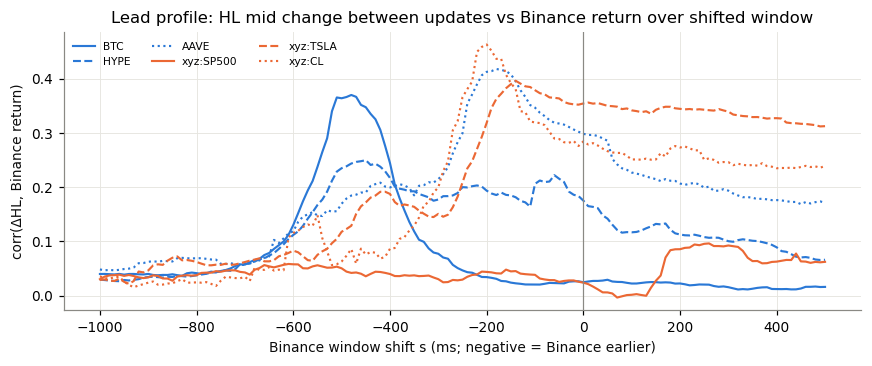

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.4))
for s in SYMS:
    ax.plot(LEAD_SHIFTS, lead_prof[s], color=C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI, lw=1.4,
            ls="-" if s in ("BTC-USD-PERP", "xyz:SP500-USD-PERP") else ("--" if s in ("HYPE-USD-PERP", "xyz:TSLA-USD-PERP") else ":"),
            label=s.replace("-USD-PERP", ""))
ax.axvline(0, color=C_MUTED, lw=0.8)
ax.set(xlabel="Binance window shift s (ms; negative = Binance earlier)", ylabel="corr(ΔHL, Binance return)",
       title="Lead profile: HL mid change between updates vs Binance return over shifted window")
ax.legend(frameon=False, fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

### 9.4 What does the Binance lead look like? (event study)
The lead profile in 9.3 is one correlation per shift. This makes it visible. A Binance **jump** is a Binance mid
move over the previous 50 ms whose size is in the top 0.5% for that pair; jumps are kept ≥ 2 s apart. Around each
jump time τ (Binance clock), both mids are sampled every 10 ms. Each path is signed by the jump direction and
measured in bps from its own value 1 s before τ. Lines are the mean across jumps.
If HL follows Binance, the HL line rises *after* the Binance line. `t50` is when a line first reaches half of
its level at +2 s, and the lag is HL t50 − Binance t50.
Caveats: HL can only step at its own blocks/updates, and any HL↔Binance clock offset slides the HL line sideways.

In [27]:
def jump_events(s):
    b = STREAMS[f"bn_l1:{s}"]
    t = b.t.astype(float)
    r = (b.lm - b.lmid_at(t - EVT_RET_MS)) * 1e4
    cut = np.nanquantile(np.abs(r), EVT_Q)
    cand = np.where(np.abs(r) >= cut)[0]
    keep, last = [], -np.inf
    for i in cand:                       # first qualifying update, then nothing for EVT_MIN_SEP
        if t[i] - last >= EVT_MIN_SEP:
            keep.append(i); last = t[i]
    keep = np.array(keep, int)
    return t[keep], np.sign(r[keep]), cut

def t50(path):
    final = path[-1]
    idx = np.where((EVT_WIN >= -200) & (path >= 0.5 * final))[0]
    return EVT_WIN[idx[0]] if len(idx) and final > 0 else np.nan

evt, evt_rows = {}, []
for s in SYMS:
    tau, sg, cut = jump_events(s)
    hl, bn = STREAMS[f"hl_l1:{s}"], STREAMS[f"bn_l1:{s}"]
    G = tau[:, None] + EVT_WIN[None, :]
    pb = (bn.lmid_at(G) - bn.lmid_at(tau - 1000)[:, None]) * 1e4 * sg[:, None]
    ph = (hl.lmid_at(G) - hl.lmid_at(tau - 1000)[:, None]) * 1e4 * sg[:, None]
    ok = ~np.isnan(pb).any(1) & ~np.isnan(ph).any(1) & (tau - 1000 > hl.t[0])
    evt[s] = {"bn": pb[ok].mean(0), "hl": ph[ok].mean(0), "tau": tau[ok], "sign": sg[ok]}
    b50, h50 = t50(evt[s]["bn"]), t50(evt[s]["hl"])
    evt_rows.append({"symbol": s, "group": GROUP[s], "n jumps": int(ok.sum()), "jump cut bps (50ms)": cut,
                     "Binance move @+2s bps": evt[s]["bn"][-1], "HL move @+2s bps": evt[s]["hl"][-1],
                     "HL/Binance @+2s": evt[s]["hl"][-1] / evt[s]["bn"][-1],
                     "Binance t50 ms": b50, "HL t50 ms": h50, "lag (HL−Binance) ms": h50 - b50})
evt_tab = pd.DataFrame(evt_rows).set_index("symbol")
evt_tab

,group,n jumps,jump cut bps (50ms),Binance move @+2s bps,HL move @+2s bps,HL/Binance @+2s,Binance t50 ms,HL t50 ms,lag (HL−Binance) ms
symbol,,,,,,,,,
BTC-USD-PERP,crypto,61,1.7943,2.9377,2.6245,0.8934,0,530,530
HYPE-USD-PERP,crypto,60,4.4061,5.0781,4.9502,0.9748,0,210,210
AAVE-USD-PERP,crypto,32,4.5713,6.4907,6.2887,0.9689,0,330,330
xyz:SP500-USD-PERP,tradfi,17,1.3121,1.4592,1.3841,0.9485,0,600,600
xyz:TSLA-USD-PERP,tradfi,6,3.5604,3.9418,3.5677,0.9051,0,600,600
xyz:CL-USD-PERP,tradfi,3,5.0587,9.4365,8.4356,0.8939,0,370,370


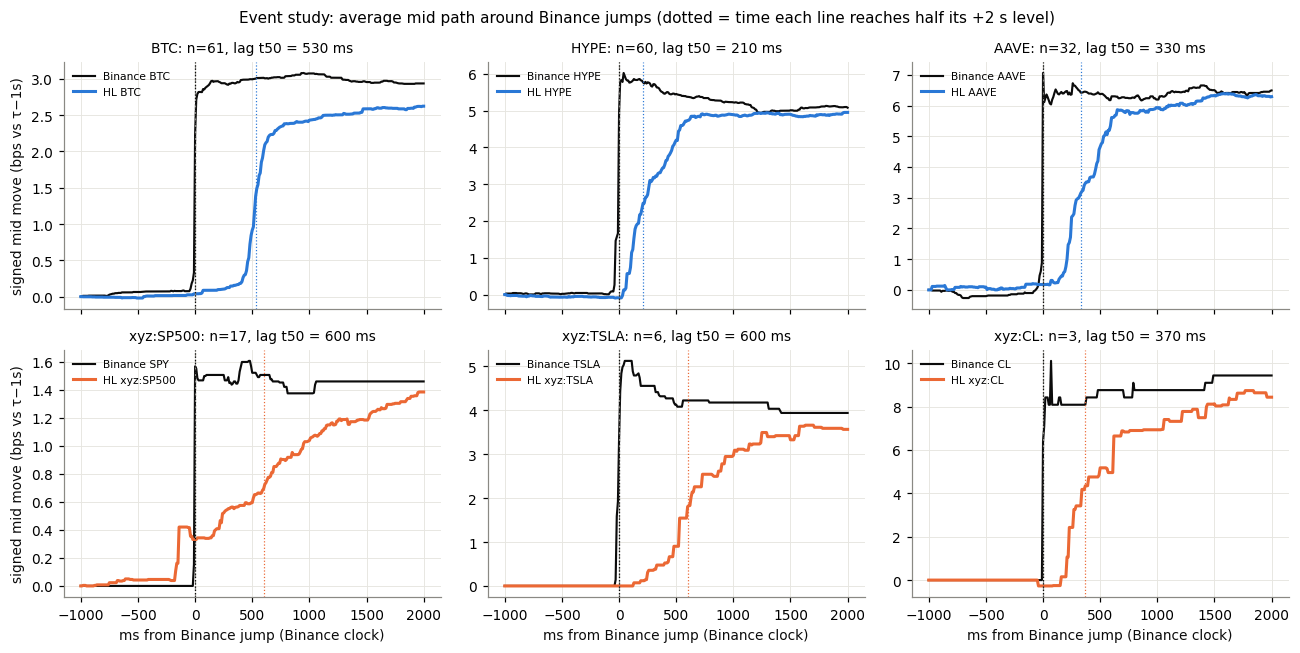

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, s in zip(axes.ravel(), SYMS):
    col = C_CRYPTO if GROUP[s] == "crypto" else C_TRADFI
    ax.plot(EVT_WIN, evt[s]["bn"], color=C_INK, lw=1.4, label=f"Binance {PAIRS[s].replace('-USDT-PERP', '')}")
    ax.plot(EVT_WIN, evt[s]["hl"], color=col, lw=2, label=f"HL {s.replace('-USD-PERP', '')}")
    ax.axvline(0, color=C_MUTED, lw=0.8, ls="--")
    r = evt_tab.loc[s]
    for v, c in [(r["Binance t50 ms"], C_INK), (r["HL t50 ms"], col)]:
        if np.isfinite(v):
            ax.axvline(v, color=c, lw=0.8, ls=":")
    ax.set_title(f"{s.replace('-USD-PERP', '')}: n={int(r['n jumps'])}, lag t50 = {r['lag (HL−Binance) ms']:.0f} ms", fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("ms from Binance jump (Binance clock)")
for ax in axes[:, 0]:
    ax.set_ylabel("signed mid move (bps vs τ−1s)")
fig.suptitle("Event study: average mid path around Binance jumps (dotted = time each line reaches half its +2 s level)", fontsize=10)
plt.tight_layout(); plt.show()

**One raw example: the largest BTC jump.** Step lines are the actual quote updates, not averages. The ticks at the
bottom are HL visible blocks (any of the 6 instruments), so you can see where HL *could* have updated.

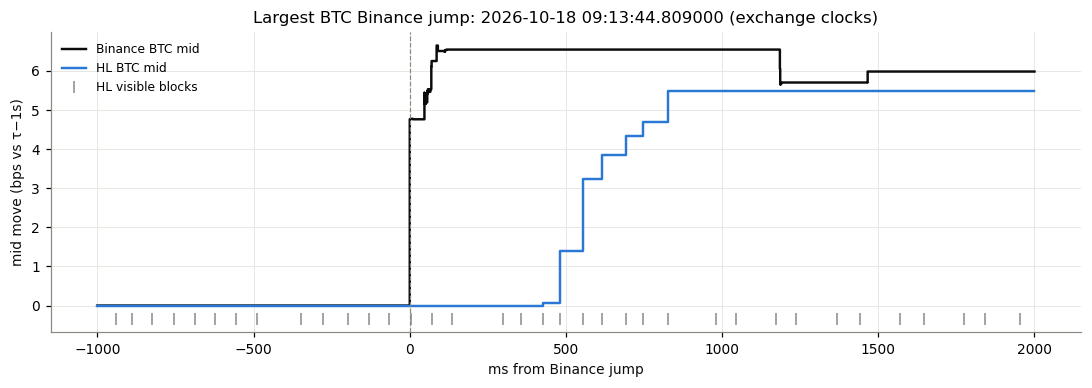

In [29]:
s = "BTC-USD-PERP"
bn, hl = STREAMS[f"bn_l1:{s}"], STREAMS[f"hl_l1:{s}"]
r_all = (bn.lmid_at(evt[s]["tau"]) - bn.lmid_at(evt[s]["tau"] - EVT_RET_MS)) * 1e4
tau0 = evt[s]["tau"][np.nanargmax(np.abs(r_all))]
lo, hi = tau0 - 1000, tau0 + 2000
fig, ax = plt.subplots(figsize=(10, 3.6))
for st, col, lab in [(bn, C_INK, "Binance BTC mid"), (hl, C_CRYPTO, "HL BTC mid")]:
    m = (st.t >= lo) & (st.t <= hi)
    tt = np.concatenate([[lo], st.t[m], [hi]]).astype(float)
    yy = np.concatenate([[st.lmid_at(lo)], st.lm[m], [st.lmid_at(hi)]])
    ax.step(tt - tau0, (yy - st.lmid_at(tau0 - 1000)) * 1e4, where="post", color=col, lw=1.6, label=lab)
bt = blk.t.values[(blk.t.values >= lo) & (blk.t.values <= hi)]
ax.plot(bt - tau0, np.full(len(bt), ax.get_ylim()[0]), "|", color=C_MUTED, ms=8, label="HL visible blocks")
ax.axvline(0, color=C_MUTED, lw=0.8, ls="--")
ax.set(xlabel="ms from Binance jump", ylabel="mid move (bps vs τ−1s)",
       title=f"Largest BTC Binance jump: {pd.to_datetime(tau0, unit='ms')} (exchange clocks)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 10. Instrument-type summary (crypto vs tradfi)

In [30]:
summ = pd.DataFrame({
    "group": {s: GROUP[s] for s in SYMS},
    "visible blocks share": q1_inst["share of all blocks visible"],
    "median gap ms": q1_inst["median gap ms"],
    "rho1 raw gap": {s: q2_inst.loc[(s, GROUP[s]), ("rho(1)", "raw gap")] for s in SYMS},
    "rho1 single-block": {s: q2_inst.loc[(s, GROUP[s]), ("rho(1)", "single-block gap")] for s in SYMS},
    **{f"Q5 F3 skill [{ln}]": q5_all[(q5_all.features == "F3 +Binance") & (q5_all.latency == ln)].set_index("set")["skill vs F0"]
       for ln in LATENCY_SCENARIOS},
    **{f"Q5 Binance gain [{ln}]": q5_all[(q5_all.features == "F3 +Binance") & (q5_all.latency == ln)].set_index("set")["gain vs prev set"]
       for ln in LATENCY_SCENARIOS},
    "event-study lag ms": evt_tab["lag (HL−Binance) ms"],
    "hazard rel. gain": haz["rel. improvement"],
    "lead peak shift ms": peak["peak shift ms"], "lead peak corr": peak["peak corr"],
    "within-gap OOS R2 (δ=10)": lead_tab.xs(10, level="delta ms")["OOS R2"],
}).loc[SYMS]
summ

,group,visible blocks share,median gap ms,rho1 raw gap,rho1 single-block,"Q5 F3 skill [N(0.50, 0.05) ms]",Q5 F3 skill [measured ts_recv],"Q5 Binance gain [N(0.50, 0.05) ms]",Q5 Binance gain [measured ts_recv],event-study lag ms,hazard rel. gain,lead peak shift ms,lead peak corr,within-gap OOS R2 (δ=10)
BTC-USD-PERP,crypto,0.3207,134.0,0.212,-0.205,0.1341,0.1242,0.0166,0.0180,530.0,0.0008,-480.0,0.3697,1.3238e-05
HYPE-USD-PERP,crypto,0.2552,133.0,0.232,-0.174,0.1686,0.1418,0.0458,0.0531,210.0,0.0045,-450.0,0.2495,1.3300e-02
AAVE-USD-PERP,crypto,0.1280,200.0,0.170,-0.172,0.1597,0.1425,0.0641,0.0592,330.0,0.0116,-180.0,0.4176,1.0405e-01
xyz:SP500-USD-PERP,tradfi,0.0817,307.0,0.202,-0.132,0.1392,0.1051,0.0009,0.0046,600.0,-0.0003,260.0,0.0962,5.4220e-04
xyz:TSLA-USD-PERP,tradfi,0.0315,422.0,0.166,-0.310,0.1031,0.0518,0.0368,0.0206,600.0,0.0172,-140.0,0.3959,1.4736e-01
xyz:CL-USD-PERP,tradfi,0.0488,341.0,0.230,-0.184,0.1735,0.1414,0.0152,0.0108,370.0,0.0035,-200.0,0.4627,5.8487e-02


## 11. Trials

In [31]:
print(f"n_trials (model variants evaluated in this notebook): {len(TRIALS)}")
pd.DataFrame(TRIALS).groupby("q").size()

n_trials (model variants evaluated in this notebook): 155


q
Q-hazard    14
Q-lead      18
Q1           4
Q3          63
Q4          14
Q5          42
dtype: int64

## 12. Findings (run of 2026-10-19 on the 2026-10-18 data; 7.2 h, n_trials = 155)

**Weak points first**
* 7.2 h of **one Sunday morning** (03:14–10:23 UTC), one train/test split. US equity and oil markets were closed, so the
  `xyz:` perps were off-hours.
* There's no block height in the feed, so block counts are *inferred*.
* Q1–Q4, the hazard and the lead analysis are exchange-time descriptions. Only Q5 applies latency.
* The HL↔Binance clock offset is unverified. Every lead/lag number below includes it.
* The event study is thin for tradfi (SP500 17 jumps, TSLA 6, CL 3). Read those panels as anecdotes.

**Q1 Distribution.** Every candidate is formally rejected (chi² p ≈ 0, n = 80k). The best fit is a lattice:
**a 67.0 ms clock (σ 1.5 ms) carrying 65% of blocks, the rest spread over ~45–100 ms**. Mean block 68.1 ms (14.7/s);
~53% of blocks are visible to the 6-instrument union. Exponential (memoryless) is badly wrong.

**Q2 Autocorrelation.** Raw gaps: ρ(1) = 0.18, almost all of it visibility clustering. The clock: single-block gaps have
**ρ(1) = −0.20 vs −0.001 expected from ms rounding**. A short block is followed by a longer one (prev ≤ 55 ms → next
median 73; prev 80–100 → 66). The clock looks schedule-anchored with catch-up.

**Q3 Activity.** It doesn't move the clock: single-block next-gap medians are 67 vs 67 ms after busy vs quiet blocks
(AUC 0.48–0.51). The big raw effects are visibility.

**Q4 Lags.** Jointly significant everywhere. OOS R² of log next gap: 0.09 (union), 0.08–0.22 (instruments).

**Q5 Forecast within an interval, with latency.**
* *N(0.50, 0.05) ms:* identical to zero latency (0.5 ms is below the 1 ms timestamp resolution). Union skill vs
  unconditional is **14.1% [13.4, 14.8]**, 10–17% per instrument. The 80% interval covers 79%; width 154 → 128 ms.
* *Measured `ts_recv`:* you learn about block n a median **280 ms** after it happened (~4 blocks later). The target becomes
  the residual wait to the next block after that moment (median 58 ms). Union skill drops to **10.7% [10.1, 11.3]**;
  per instrument 5% (TSLA) to 14%. Coverage stays at 72–79%.
* In both scenarios Binance adds the most for HYPE (+4.6 / +5.3%) and AAVE (+6.4 / +5.9%), and ≈ 0 for SP500 (+0.1 / +0.5%).

**Binance inside the gap: timing.** The hazard gain is tiny (union 0.04% log-loss, ≤ 1.7% per instrument) and the clock
test is null. Binance predicts when an HL *instrument reprices*, not when the chain commits a block.

**Binance inside the gap: price (what the lead looks like, §9.4).** After a Binance jump, HL's mid reaches half the
Binance move **210 ms (HYPE), 330 ms (AAVE), 530 ms (BTC)** later. By +2 s it has caught up 89–97%. In the largest BTC
jump, HL's BTC mid doesn't move for ~430 ms and then steps up over ~400 ms. There are also **no visible HL blocks
from ~130 to ~300 ms** after that jump (one example; worth checking whether blocks stall after big moves).
Tradfi: TSLA/CL follow Binance with a lag similar to the crypto pairs, on very few events. SP500 vs SPY has no lead
(the correlation profile peaks at +260 ms).

**Crypto vs tradfi.** Same chain clock. The differences are visibility (TSLA sees 3% of blocks, BTC 32%) and how tightly
the HL mid tracks the Binance pair.

**Open questions for Mark**
1. The ~200 ms floor on HL `ts_recv − ts_exch` rules out 0.5 ms end-to-end (see the chat note). Is the 0.5 ms you heard
   about something else, e.g. block-commit → publish inside the node?
2. Do you want to test the "phase-locked 67 ms grid with catch-up" idea directly? What would falsify it?
3. Do blocks stall after large moves? (the 130–300 ms hole in the BTC example) That's testable on the union stream.
4. Rerun on weekday data, including the US cash session, before reading anything into the tradfi rows.